# Proyecto integrador: métodos numéricos
## Segunda entrega: implementación reproducible

**Universidad Externado de Colombia · Ciencia de Datos · 2026-2**  
Equipo: Ailyn Sofía Gómez Rodríguez, Julián Camilo Jiménez y Julián Steven Duarte. Docente: Edwin Fernando Muñoz Chipatecua.

Este cuaderno implementa M1 y M2 del artículo de Jerezano, Chicharro y Garrido-Sáez, y los compara con Newton modificado, Steffensen modificado y KK. Ejecute las celdas en orden. No se requieren archivos externos ni números aleatorios, por lo que no hay semilla pseudoaleatoria. Las semillas iniciales de cada corrida sí quedan fijadas.

**Entorno:** Python 3.10 o posterior, con `mpmath`, `pandas` y `matplotlib`. Instale con `%pip install mpmath pandas matplotlib` si hace falta.

## 1. Métodos

Para una raíz de multiplicidad conocida $m$, se define $w_k=x_k+\beta g(x_k)^2$, la pendiente secante $D_k=[g(w_k)-g(x_k)]/(w_k-x_k)$, el predictor $y_k=x_k-mg(x_k)/D_k$ y $t_k=\exp(\mathrm{Log}(g(y_k)/g(x_k))/m)$ con el logaritmo principal complejo. El corrector es $x_{k+1}=x_k-mH(t_k)g(x_k)/D_k$.

M1 usa $H_1(t)=1+t+2t^2$ y M2 usa $H_2(t)=(1-t)/(1-2t)$. Bajo las hipótesis del artículo tienen orden teórico cuatro. Newton modificado y Steffensen modificado son referencias de orden dos para raíces múltiples. También se incluye KK, competidor sin derivadas de orden cuatro.

In [1]:
# ===== Configuración reproducible: precisión, tolerancia y beta =====
from time import perf_counter
from pathlib import Path
import mpmath as mp
import math
import pandas as pd
import matplotlib.pyplot as plt
# Precisión fijada antes de crear los números decimales.
TOL=mp.mpf('1e-25')
MAX_ITER=100
BETA=mp.mpf('0.01')
print('precision',mp.mp.dps,'tolerancia',mp.nstr(TOL))

precision 15 tolerancia 1.0e-25


## 2. Problemas de prueba deterministas

Para Planck, la ecuación base es $e^{-x}-1+x/5=0$ y la función probada es su cubo; el término es lineal en $x$, no $x^3/5$. También hay una raíz en cero, pero estudiamos la raíz positiva no nula cercana a $4.9651$. Las raíces de referencia sirven para medir el error y no se entregan a los solucionadores. Cada función tiene dos semillas fijadas.

In [2]:
# ===== Definición de funciones, derivadas y raíces de referencia =====
# Polinomio cúbico con raíz doble objetivo en 1.75.
def g1(x): return x**3-mp.mpf('5.22')*x**2+mp.mpf('9.0825')*x-mp.mpf('5.2675')
def dg1(x): return 3*x**2-mp.mpf('10.44')*x+mp.mpf('9.0825')
# Ecuación base de Planck; g2 eleva su residuo al cubo.
def hp(x): return mp.exp(-x)-1+x/5
def g2(x): return hp(x)**3
def dg2(x): return 3*hp(x)**2*(-mp.exp(-x)+mp.mpf(1)/5)
def g3(x): return x**9-29*x**8+349*x**7-2261*x**6+8455*x**5-17663*x**4+15927*x**3+6993*x**2-24732*x+12960
def dg3(x): return 9*x**8-232*x**7+2443*x**6-13566*x**5+42275*x**4-70652*x**3+47781*x**2+13986*x-24732
# alpha se usa para medir error; no se pasa a los iteradores.
# Cada elemento agrupa función, multiplicidad, raíz de referencia y semillas.
benchmarks=[
 {'id':'g1 doble','g':g1,'dg':dg1,'m':2,'alpha':mp.mpf('1.75'),'seeds':['1.9','3.0']},
 {'id':'g2 Planck triple','g':g2,'dg':dg2,'m':3,'alpha':mp.findroot(lambda z: mp.exp(-z)-1+z/5, mp.mpf('5')),'seeds':['5.3','10.0']},
 {'id':'g3 cuádruple','g':g3,'dg':dg3,'m':4,'alpha':mp.mpf('3.0'),'seeds':['2.8','3.4']}]
print('Problemas definidos:',len(benchmarks))

Problemas definidos: 3


## 3. Solucionador y registro de fallos

El solucionador cuenta evaluaciones de $g$ y $g'$, conserva los iterados y registra el estado. La potencia fraccionaria usa la rama principal compleja. La corrida termina solo si **paso y residuo** cumplen la tolerancia. Nodos coincidentes, divisiones no definidas y límite de iteraciones se reportan explícitamente. El ACOC es un indicador local, no una prueba del orden.

In [3]:
# ===== Solucionador: secantes, correctores, parada y conteos =====
# Rama principal para definir la potencia fraccionaria.
def principal_root(z,m):
 # Rama principal compleja, como en la definicion del articulo.
 z=mp.mpc(z)
 if z==0: return mp.mpc(0)
 return mp.exp(mp.log(z)/m)
def dd(g,a,b):
 if a==b: raise ZeroDivisionError('nodos coincidentes')
 return (g(a)-g(b))/(a-b)
# Cuenta por separado evaluaciones de función y derivada.
def solve(method,g,dg,m,x0,beta=BETA,tol=TOL,max_iter=MAX_ITER):
 n_g=0; n_dg=0
 def fg(z):
  nonlocal n_g
  n_g+=1
  return g(z)
 def fdg(z):
  nonlocal n_dg
  n_dg+=1
  return dg(z)
 # Se inicia desde la semilla y se guarda el primer residuo.
 x=mp.mpf(x0); gx=fg(x); xs=[x]; steps=[]; residuals=[abs(gx)]; status='maximo de iteraciones'; start=perf_counter()
 # Cada vuelta calcula como máximo un nuevo iterado.
 for k in range(1,max_iter+1):
  if abs(gx)<=tol and steps and steps[-1]<=tol:
   status='convergio'; break
  try:
   if method in ('M1','M2','Steffensen','KK'):
    # M1/M2 perturban con g(x)^2; Steffensen y KK con g(x).
    w=x+beta*(gx**2 if method in ('M1','M2') else gx)
    # Si w se absorbe en x, la pendiente secante ya no se puede formar.
    if w==x: status='estancamiento w=x'; break
    gw=fg(w); d=(gw-gx)/(w-x)
    # Evita dividir por una pendiente secante nula.
    if d==0: raise ZeroDivisionError('pendiente nula')
    if method=='Steffensen': xn=x-m*gx/d
    # KK agrega otra secante entre w e y para formar su corrector.
    elif method=='KK':
     y=x-m*gx/d; gy=fg(y); t=principal_root(gy/gx,m)
     if w==y: raise ZeroDivisionError('nodos KK coincidentes')
     dwy=(gw-gy)/(w-y)
     if 1-2*t==0: raise ZeroDivisionError('polo KK')
     den=d+2*dwy
     if den==0: raise ZeroDivisionError('denominador KK nulo')
     xn=y-((m+2)*t/(1-2*t))*gx/den
     # M1 y M2 comparten predictor; cambia únicamente H(t).
    else:
     y=x-m*gx/d; t=principal_root(fg(y)/gx,m)
     if method=='M1': H=1+t+2*t**2
     else:
      if 1-2*t==0: raise ZeroDivisionError('polo H2')
      H=(1-t)/(1-2*t)
     xn=x-m*H*gx/d
   # Newton modificado es la única línea base que evalúa g prima.
   elif method=='Newton modificado':
    dx=fdg(x)
    if dx==0: raise ZeroDivisionError('derivada nula')
    xn=x-m*gx/dx
   else: raise ValueError('metodo desconocido')
   # Se registra paso, residuo y trayectoria para criterios y gráficos.
   step=abs(xn-x); gn=fg(xn); res=abs(gn); xs.append(xn); steps.append(step); residuals.append(res); x=xn; gx=gn
   if step<=tol and res<=tol: status='convergio'; break
  except (ValueError,ZeroDivisionError,OverflowError) as exc:
   status='fallo: '+str(exc); break
 # ACOC aproxima el orden con tres diferencias sucesivas.
 acoc=None
 if len(xs)>=4:
  e1,e2,e3=abs(xs[-1]-xs[-2]),abs(xs[-2]-xs[-3]),abs(xs[-3]-xs[-4])
  if min(e1,e2,e3)>0 and mp.log(e2/e3)!=0: acoc=float(mp.log(e1/e2)/mp.log(e2/e3))
 return {'status':status,'iterations':len(steps),'x':x,'step':steps[-1] if steps else mp.inf,'residual':abs(gx),'acoc':acoc,'ms':1000*(perf_counter()-start),'g_evals':n_g,'dg_evals':n_dg,'residuals':residuals,'xs':xs}
print('Solucionador definido')

Solucionador definido


## 4. Corridas, tabla y CSV

Se comparan cinco métodos en cada función y semilla. El tiempo es el promedio de 50 ejecuciones, por lo que depende del equipo. Se registran error frente a la raíz de referencia, residuo, estado y conteos; estos incluyen la evaluación del nuevo residuo. La tabla se exporta a `resultados_fase2.csv` en la carpeta `resultados`.

In [4]:
# ===== Corridas y exportación de resultados =====
methods=['M1','M2','Newton modificado','Steffensen','KK']
# rows alimenta la tabla y history conserva los residuos para la gráfica.
rows=[]; history={}
# Ejecuta cada método para cada benchmark y semilla fijada.
for b in benchmarks:
 for seed in b['seeds']:
  for method in methods:
   r=solve(method,b['g'],b['dg'],b['m'],seed); times=[r['ms']]
   # Repeticiones adicionales para estimar el tiempo promedio.
   for _ in range(49): times.append(solve(method,b['g'],b['dg'],b['m'],seed)['ms'])
   r['ms']=sum(times)/len(times); history[(b['id'],seed,method)]=r
   rows.append({'problema':b['id'],'m':b['m'],'semilla':seed,'metodo':method,'estado':r['status'],'iteraciones':r['iterations'],'eval_g':r['g_evals'],'eval_gprima':r['dg_evals'],'error_abs':mp.nstr(abs(r['x']-b['alpha']),8),'residuo':mp.nstr(r['residual'],8),'ACOC':r['acoc'],'tiempo_ms':round(r['ms'],4)})
results=pd.DataFrame(rows)
display(results)
cwd=Path.cwd()
if (cwd/'segunda entrega'/'resultados').is_dir():
    project_dir=cwd/'segunda entrega'
elif (cwd.parent/'resultados').is_dir():
    project_dir=cwd.parent
else:
    project_dir=cwd
results_dir=project_dir/'resultados'
results_dir.mkdir(exist_ok=True)
csv_path=results_dir/'resultados_fase2.csv'
# Exporta la tabla de resultados para consultarla por fuera.
results.to_csv(csv_path,index=False)
print('Guardado:',csv_path)

,problema,m,semilla,metodo,estado,iteraciones,eval_g,eval_gprima,error_abs,residuo,ACOC,tiempo_ms
0,g1 doble,2,1.9,M1,estancamiento w=x,2,7,0,0.00037237548,4.2115396e-9,NaN,0.2339
1,g1 doble,2,1.9,M2,fallo: pendiente nula,2,8,0,0.012096416,6.1596856e-6,NaN,0.2776
2,g1 doble,2,1.9,Newton modificado,convergio,6,7,6,5.3170015e-9,0.0,NaN,0.2375
3,g1 doble,2,1.9,Steffensen,fallo: pendiente nula,7,16,0,6.9823322e-5,1.465974e-10,-1.019516,0.3714
4,g1 doble,2,1.9,KK,fallo: pendiente nula,2,8,0,3.4850567e-5,3.6479264e-11,NaN,0.2836
5,g1 doble,2,3.0,M1,estancamiento w=x,3,10,0,0.00074544971,1.7085103e-8,1.112895,0.3897
6,g1 doble,2,3.0,M2,fallo: pendiente nula,3,11,0,0.011129594,5.0946347e-6,2.939473,0.4431
7,g1 doble,2,3.0,Newton modificado,convergio,8,9,8,1.3487376e-9,0.0,NaN,0.2922
8,g1 doble,2,3.0,Steffensen,fallo: pendiente nula,6,14,0,2.4444799e-5,1.7912782e-11,1.581398,0.3228
9,g1 doble,2,3.0,KK,fallo: pendiente nula,4,14,0,2.6919958e-5,2.1760371e-11,5.743366,0.6093


Guardado: /home/julianxd/code/metodos/segunda entrega/resultados/resultados_fase2.csv


## 5. Sensibilidad a $\beta$

M1 y M2 se repiten para $\beta=0.001$, $0.01$ y $1.0$, en cada benchmark y semilla. El barrido compara las trayectorias ensayadas; no calcula una cuenca completa de atracción. También conserva fallos y estancamientos.

In [5]:
# ===== Barrido de beta para comparar trayectorias =====
# Se exporta una fila por función, semilla, beta y método.
beta_records=[]
# Se modifica beta y se mantienen fijos los demás datos.
for b in benchmarks:
    for seed in b["seeds"]:
        for beta_value in (mp.mpf('0.001'),mp.mpf('0.01'),mp.mpf('1.0')):
            for method in ("M1","M2"):
                r=solve(method,b["g"],b["dg"],b["m"],seed,beta=beta_value)
                beta_records.append({
                    "problema":b["id"],"semilla":seed,"beta":mp.nstr(beta_value),
                    "metodo":method,"estado":r["status"],
                    "iteraciones":r["iterations"],
                    "error_abs":mp.nstr(abs(r["x"]-b["alpha"]),8),
                    "residuo":mp.nstr(r["residual"],8)})
beta_sensitivity=pd.DataFrame(beta_records)
display(beta_sensitivity)
beta_sensitivity.to_csv(results_dir/"sensibilidad_beta.csv",index=False)
print("Sensibilidad exportada:",results_dir/"sensibilidad_beta.csv")

,problema,semilla,beta,metodo,estado,iteraciones,error_abs,residuo
0,g1 doble,1.9,0.001,M1,fallo: pendiente nula,3,0.012926715,7.1730529e-6
1,g1 doble,1.9,0.001,M2,fallo: pendiente nula,2,0.012019095,6.0700218e-6
2,g1 doble,1.9,0.01,M1,estancamiento w=x,2,0.00037237548,4.2115396e-9
3,g1 doble,1.9,0.01,M2,fallo: pendiente nula,2,0.012096416,6.1596856e-6
4,g1 doble,1.9,1.0,M1,estancamiento w=x,2,0.00027734866,2.3290028e-9
5,g1 doble,1.9,1.0,M2,estancamiento w=x,2,7.9740212e-5,1.9126212e-10
6,g1 doble,3.0,0.001,M1,estancamiento w=x,3,0.0028702205,2.7079033e-7
7,g1 doble,3.0,0.001,M2,fallo: pendiente nula,2,0.011665248,5.6697241e-6
8,g1 doble,3.0,0.01,M1,estancamiento w=x,3,0.00074544971,1.7085103e-8
9,g1 doble,3.0,0.01,M2,fallo: pendiente nula,3,0.011129594,5.0946347e-6


Sensibilidad exportada: /home/julianxd/code/metodos/segunda entrega/resultados/sensibilidad_beta.csv


## 6. Diagnóstico en `float64`

M1 y M2 se ejecutan en doble precisión para $g_1$, $m=2$, $\beta=0.01$ y $x_0=1.9$. Se observa si la perturbación desaparece al sumarla a $x$ y produce $w=x$. El umbral depende de la trayectoria y del redondeo.

In [6]:
# ===== Diagnóstico con números float64 =====
# Repite M1/M2 en aritmética binaria de doble precisión.
def solve_float64(method,x0=1.9,max_iter=30):
    def gf(x):
        return x**3-5.22*x**2+9.0825*x-5.2675
    x=float(x0); last_res=abs(gf(x)); status="maximo de iteraciones"; count=0
    for k in range(1,max_iter+1):
        gx=gf(x); w=x+0.01*(gx**2)
        # La igualdad exacta detecta que la perturbación se perdió por redondeo.
        if w==x:
            status="absorcion: w=x"; break
        d=(gf(w)-gx)/(w-x)
        if d==0:
            status="pendiente secante nula"; break
        y=x-2*gx/d; gy=gf(y); ratio=gy/gx
        # En este diagnóstico float real, una razón negativa no tiene raíz real.
        if ratio<0:
            status="sin raiz real"; break
        t=ratio**0.5
        H=1+t+2*t*t if method=="M1" else (1-t)/(1-2*t)
        if method=="M2" and 1-2*t==0:
            status="polo H2"; break
        xn=x-2*H*gx/d; count=k; last_res=abs(gf(xn))
        if abs(xn-x)<1e-14 and last_res<1e-14:
            x=xn; status="convergio"; break
        x=xn
    return {"metodo":method,"estado":status,"iteraciones":count,
            "ultimo_x":x,"residuo":last_res}
float64_results=pd.DataFrame([solve_float64("M1"),solve_float64("M2")])
display(float64_results)

,metodo,estado,iteraciones,ultimo_x,residuo
0,M1,absorcion: w=x,2,1.750372,4.211540e-09
1,M2,pendiente secante nula,2,1.762096,6.159686e-06


## 7. Gráfico de convergencia

Se grafica el residuo de cada método para $g_1$ desde $1.9$. La escala vertical logarítmica representa residuos positivos; consulte la tabla de estados para interpretar curvas incompletas.

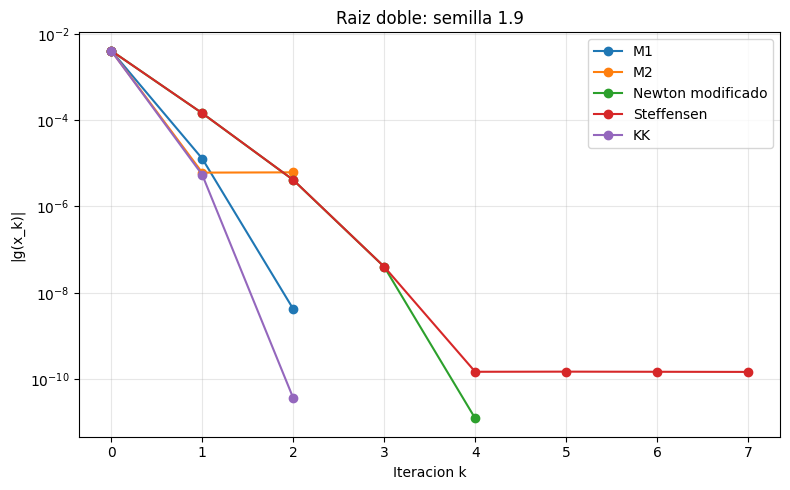

In [7]:
# ===== Gráfico de residuos para g1 =====
# Grafica residuos positivos para g1 y semilla 1.9.
fig,ax=plt.subplots(figsize=(8,5))
b=benchmarks[0]
for method in methods:
 r=history[(b['id'],'1.9',method)]
 ys=[float(q) for q in r['residuals'] if q>0]
 if ys: ax.semilogy(range(len(ys)),ys,marker='o',label=method)
ax.set(xlabel='Iteracion k',ylabel='|g(x_k)|',title='Raiz doble: semilla 1.9')
ax.grid(True,which='both',alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

## 8. Lectura de resultados y declaración

Para $g_1$ desde $1.9$, M1 converge en cinco pasos y M2 y KK alcanzan errores pequeños, pero se estancan. Desde $3.0$, Newton, Steffensen y KK convergen; M1 falla y M2 se estanca. En $g_2$, M1 y M2 se estancan desde ambas semillas; KK converge desde $5.3$ y se estanca desde $10.0$. En $g_3$ convergen todos con las semillas probadas. La respuesta cambia con semilla y con $\beta$.

La Tabla 1 del artículo informa siete pasos para M1 y M2 y seis para KK desde $g_1$ con semilla $1.9$. No es comparación directa: se usaron tolerancias y criterios de parada distintos. Estas corridas no confirman numéricamente el orden cuatro; se necesitarían más semillas e historiales antes del estancamiento. Los benchmarks son matemáticos, no datos experimentales, y el tiempo depende del equipo.

**Integridad académica.** Se utilizó una herramienta de IA para apoyar la revisión del plan, la organización del código y la redacción. La guía permite este apoyo si se declara; no reemplaza la comprensión ni la implementación del equipo. Los integrantes deben verificar fórmulas y resultados y poder sustentar el trabajo.

## Referencias

J. H. Jerezano, F. I. Chicharro y N. Garrido-Sáez, “Derivative-free optimal multiple-root finding family of iterative methods”, *Computational and Applied Mathematics*, vol. 45, art. 304, 2026. [doi:10.1007/s40314-026-03702-8](https://doi.org/10.1007/s40314-026-03702-8).

Universidad Externado de Colombia, Departamento de Matemáticas, *Guía del Proyecto Integrador: Métodos Numéricos*, 2026.